# 02 · Modelo 1 — Previsão de prazo (regressão)
**Projeto ZelaBairro · Global Solution 2026/2 · IA & Chatbot**

**Integrantes (turma 1TDSPV):** Leonardo Afonço Sousa (RM 573982) · Syang Cristina Gomes Souza (RM 569259) ·
Matheus Jones Sousa de Freitas (RM 573559) · Vitor Goncalves de Souza (RM 569023) · Joao Machado Nascimento (RM 572364)

**Pergunta:** dado o tipo de problema, a subprefeitura e quando foi aberto, em quantos dias ele deve ser resolvido?

* Alvo: `dias_para_resolver`
* Entradas: `categoria`, `subprefeitura`, `mes`, `dia_semana`
* Caminho seguido (como nas Aulas 05 e 06): começamos pelo **modelo que chuta** (baseline), depois os modelos **interpretáveis** vistos em aula
  (**Regressão Linear** e **Árvore de Decisão**) e só então o **Random Forest**, que tem mais acurácia mas é mais "caixa preta"
* Algoritmo final: `RandomForestRegressor` treinado sobre **log(1 + dias)**
* Métricas: **MAE, RMSE e R²** (no conjunto de teste)

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = os.path.abspath("..")           # este notebook roda dentro de notebooks/
sys.path.insert(0, RAIZ)               # para importar ml_utils e chatbot
from chatbot.intents import CATEGORIAS # tabela 6.4 do Documento Base (prazos e gravidades)

CAMINHO_DADOS = os.path.join(RAIZ, "data", "dados_sp156.csv")
df = pd.read_csv(CAMINHO_DADOS)
print(f"{len(df):,} linhas e {df.shape[1]} colunas carregadas de {os.path.relpath(CAMINHO_DADOS, RAIZ)}")
df.head()

982,475 linhas e 9 colunas carregadas de data/dados_sp156.csv


,categoria,subprefeitura,data_abertura,data_encerramento,mes,dia_semana,dias_para_resolver,nr_prazo_dias,atrasou
0,Descarte irregular de lixo,Freguesia/Brasilândia,2020-01-01,2020-03-17,1,2,76,10,1
1,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-01-14,1,2,13,15,0
2,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-03-16,1,2,75,15,1
3,Buraco na via,Santo Amaro,2020-01-01,2020-01-08,1,2,7,15,0
4,Buraco na via,São Mateus,2020-01-01,2020-04-23,1,2,113,15,1


## 1. Preparação

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from ml_utils import FEATURES, montar_pipeline, montar_regressor

SEED = 42
X, y = df[FEATURES], df["dias_para_resolver"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"treino: {len(X_treino):,} | teste: {len(X_teste):,} | features: {FEATURES}")

treino: 785,980 | teste: 196,495 | features: ['categoria', 'subprefeitura', 'mes', 'dia_semana']


**Por que precisamos transformar as entradas:** os algoritmos só entendem números, mas `categoria` e `subprefeitura` são textos.
`montar_pipeline` e `montar_regressor` (em `ml_utils.py`) fazem o **one-hot**: cada valor vira uma coluna 0/1 (ex.: `categoria_Buraco na via = 1`).
`mes` e `dia_semana` também viram categorias, porque dezembro não é "maior" que janeiro. O `Pipeline` é a "esteira" da Aula 02:
transforma e treina sempre na mesma ordem, e fica num módulo à parte para que o `.joblib` possa ser carregado pela API Flask.
**Normalização Min-Max não se aplica aqui:** depois do one-hot todas as entradas já são 0 ou 1.

## 2. Baseline e comparação de modelos

In [3]:
def avaliar(nome, pipe):
    p = pipe.predict(X_teste)
    return {"modelo": nome, "MAE": mean_absolute_error(y_teste, p),
            "RMSE": float(np.sqrt(mean_squared_error(y_teste, p))), "R2": r2_score(y_teste, p)}

RF = dict(n_estimators=60, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
ARVORE = dict(max_depth=10, min_samples_leaf=50, random_state=SEED)   # limitar a árvore evita overfitting (Aula 06)
candidatos = {
    "1. Modelo que chuta a mediana geral (baseline)": montar_pipeline(DummyRegressor(strategy="median")),
    "2. Regressão Linear, dias brutos": montar_pipeline(LinearRegression()),
    "3. Árvore de Decisão, dias brutos": montar_pipeline(DecisionTreeRegressor(**ARVORE)),
    "4. Árvore de Decisão, log(1+dias)": montar_regressor(DecisionTreeRegressor(**ARVORE)),
    "5. Random Forest, dias brutos, sem mês": montar_pipeline(RandomForestRegressor(**RF)),
    "6. Random Forest, log(1+dias), COM mês": montar_regressor(RandomForestRegressor(**RF), usar_mes=True),
    "7. Random Forest, log(1+dias), SEM mês": montar_regressor(RandomForestRegressor(**RF), usar_mes=False),
}
resultados = []
for nome, pipe in candidatos.items():
    pipe.fit(X_treino, y_treino)
    resultados.append(avaliar(nome, pipe))
# baseline mais exigente: a mediana de CADA categoria (o que se faria sem IA, só com uma tabela)
med_cat = y_treino.groupby(X_treino["categoria"]).median()
p_cat = X_teste["categoria"].map(med_cat).fillna(y_treino.median())
resultados.append({"modelo": "0. Tabela de medianas por categoria (baseline sem IA)", "MAE": mean_absolute_error(y_teste, p_cat),
                   "RMSE": float(np.sqrt(mean_squared_error(y_teste, p_cat))), "R2": r2_score(y_teste, p_cat)})
pd.DataFrame(resultados).round(3).set_index("modelo")

,MAE,RMSE,R2
modelo,,,
1. Modelo que chuta a mediana geral (baseline),26.640,66.497,-0.119
"2. Regressão Linear, dias brutos",30.201,58.954,0.121
"3. Árvore de Decisão, dias brutos",28.427,57.711,0.157
"4. Árvore de Decisão, log(1+dias)",23.868,62.143,0.023
"5. Random Forest, dias brutos, sem mês",27.842,57.219,0.172
"6. Random Forest, log(1+dias), COM mês",22.872,60.193,0.083
"7. Random Forest, log(1+dias), SEM mês",23.344,60.998,0.058
0. Tabela de medianas por categoria (baseline sem IA),24.475,63.344,-0.015


**Como ler:** o MAE é o erro médio em **dias**; o RMSE pune mais os erros grandes; R² perto de 0 significa que o modelo explica pouco da variação.

**A história da comparação (trade-off acurácia × interpretabilidade, Aula 06):** a Regressão Linear e a Árvore de Decisão são fáceis de explicar,
mas, treinadas em **dias brutos**, erram mais em MAE do que a simples tabela de medianas (30,2 e 28,4 contra 24,5 dias): o tempo não cresce
"em linha reta" com as entradas e tem muitos outliers. Treinada em **log(1 + dias)**, a própria árvore já passa a tabela (23,9 dias), e o
Random Forest (várias árvores votando, Aula 05) erra menos ainda (23,3 dias sem mês). Por isso a floresta é o modelo final, mesmo sendo
menos interpretável; a árvore fica como a versão "explicável" do mesmo raciocínio (veja o desenho logo abaixo).
O tempo de resolução tem **cauda longa** (alguns chamados levam centenas de dias), e isso muda quem "ganha": a floresta em dias brutos
prevê a *média* (boa em RMSE/R², mas pior em MAE do que um baseline que chuta a mediana), enquanto a floresta em log(1+dias) prevê um valor
*típico* (melhor em MAE). Como o ZelaBairro mostra o tempo típico ao cidadão, o modelo final usa **log(1+dias)** e o MAE é a métrica principal;
o baseline que importa é a **mediana por categoria** (uma tabela simples, sem IA). Diga na apresentação o quanto o modelo ganha *além* dela.

### Como a Árvore de Decisão "pensa" (modelo caixa branca)
Uma árvore pequena (profundidade 3), treinada em log(1 + dias), mostra as regras do tipo **se… então** que a Aula 06 descreve:
nó raiz, nós de decisão e folhas. O valor da folha está em log; `np.expm1` volta para dias.

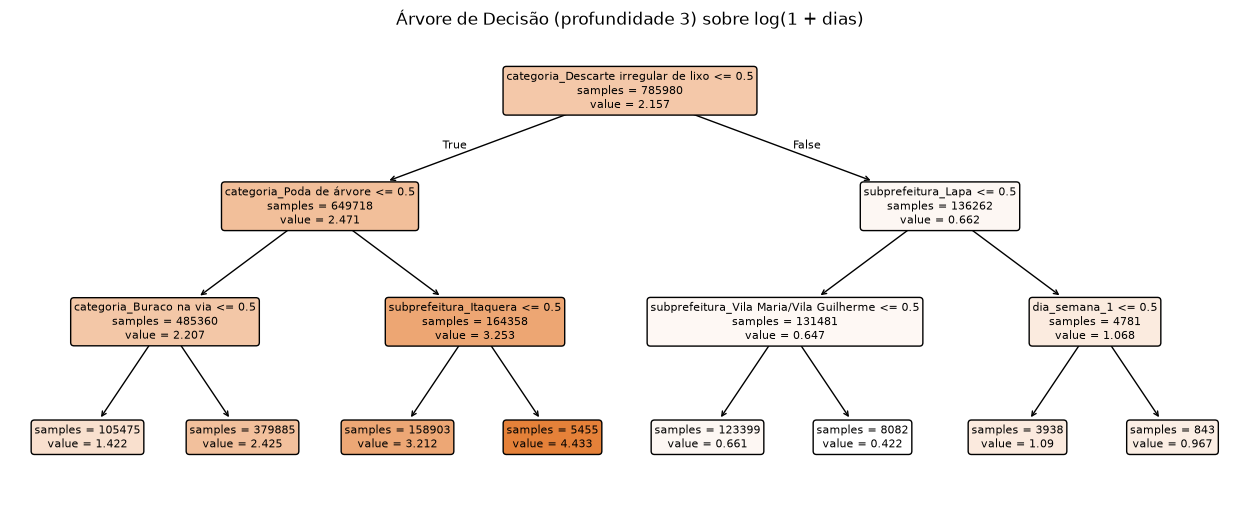

Exemplo de leitura: uma folha com value = 2.0 equivale a 6.4 dias


In [4]:
from sklearn.tree import plot_tree
arvore_pequena = montar_regressor(DecisionTreeRegressor(max_depth=3, random_state=SEED)).fit(X_treino, y_treino)
interno_arvore = arvore_pequena.regressor_
nomes_arvore = [n.replace("cat__", "") for n in interno_arvore.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(16, 6))
plot_tree(interno_arvore.named_steps["modelo"], feature_names=nomes_arvore, filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Árvore de Decisão (profundidade 3) sobre log(1 + dias)"); plt.show()
print("Exemplo de leitura: uma folha com value = 2.0 equivale a", round(float(np.expm1(2.0)), 1), "dias")

### Teste "no tempo": treinar em 2020–2022 e testar em 2023
A divisão aleatória mistura os anos; o uso real é **prever o futuro** com dados do passado. Esta comparação decide se o **mês** entra no modelo:

In [5]:
ano = pd.to_datetime(df["data_abertura"]).dt.year
tr_t = df[ano <= 2022].sample(250_000, random_state=SEED); te_t = df[ano == 2023].sample(80_000, random_state=SEED)
med = tr_t.groupby("categoria")["dias_para_resolver"].median()
linhas = [{"modelo": "Tabela de medianas por categoria (baseline sem IA)",
           "MAE": mean_absolute_error(te_t["dias_para_resolver"], te_t["categoria"].map(med).fillna(tr_t["dias_para_resolver"].median()))}]
for nome, com_mes in [("Random Forest SEM mês", False), ("Random Forest COM mês", True)]:
    m_t = montar_regressor(RandomForestRegressor(n_estimators=60, min_samples_leaf=20, n_jobs=-1, random_state=SEED), usar_mes=com_mes).fit(tr_t[FEATURES], tr_t["dias_para_resolver"])
    linhas.append({"modelo": nome, "MAE": mean_absolute_error(te_t["dias_para_resolver"], m_t.predict(te_t[FEATURES]))})
pd.DataFrame(linhas).round(2).set_index("modelo")

,MAE
modelo,
Tabela de medianas por categoria (baseline sem IA),38.73
Random Forest SEM mês,37.79
Random Forest COM mês,38.16


Treinando no passado (2020–2022) e testando em 2023, o modelo **com** mês erra **mais** que o **sem** mês: o mês aprende o que aconteceu em cada mês
daqueles anos (pandemia, mutirões), e isso não se repete. **Decisão:** o modelo final **não usa o mês** (a API continua aceitando `mes`, conforme o
contrato do Documento Base, mas o ignora). Para mudar, use `usar_mes=True` em `montar_pipeline` e retreine.

## 3. Ajuste de hiperparâmetros (busca pequena, modelo SEM mês)

In [6]:
from sklearn.model_selection import GridSearchCV

grade = {"regressor__modelo__min_samples_leaf": [10, 20, 50], "regressor__modelo__max_depth": [None, 16]}
busca = GridSearchCV(montar_regressor(RandomForestRegressor(n_estimators=60, n_jobs=-1, random_state=SEED)), grade,
                     scoring="neg_mean_absolute_error", cv=3, n_jobs=1)
# A busca roda numa AMOSTRA do treino (com ~790 mil linhas, a busca completa levaria muitos minutos);
# o modelo final é então treinado com TODO o conjunto de treino.
amostra = X_treino.sample(min(30_000, len(X_treino)), random_state=SEED).index
busca.fit(X_treino.loc[amostra], y_treino.loc[amostra])
print("Melhores parâmetros (busca na amostra):", busca.best_params_)
print(f"MAE médio na validação cruzada (amostra): {-busca.best_score_:.2f} dias")

Melhores parâmetros (busca na amostra): {'regressor__modelo__max_depth': None, 'regressor__modelo__min_samples_leaf': 50}
MAE médio na validação cruzada (amostra): 23.56 dias


## 4. Modelo final e avaliação no teste

In [7]:
melhores = {k.replace("regressor__modelo__", ""): v for k, v in busca.best_params_.items()}
modelo = montar_regressor(RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED, **melhores)).fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
base = candidatos["1. Modelo que chuta a mediana geral (baseline)"]
metricas = {
    "MAE": float(mean_absolute_error(y_teste, previsoes)),
    "RMSE": float(np.sqrt(mean_squared_error(y_teste, previsoes))),
    "R2": float(r2_score(y_teste, previsoes)),
    "baseline_mediana_MAE": float(mean_absolute_error(y_teste, base.predict(X_teste))),
    "baseline_mediana_por_categoria_MAE": float(mean_absolute_error(y_teste, p_cat)),
    "linhas_treino": int(len(X_treino)), "linhas_teste": int(len(X_teste)),
}
pd.Series(metricas).round(3).to_frame("valor")

,valor
MAE,23.343
RMSE,61.005
R2,0.058
baseline_mediana_MAE,26.640
baseline_mediana_por_categoria_MAE,24.475
linhas_treino,785980.000
linhas_teste,196495.000


In [8]:
amostra_cv = X.sample(min(60_000, len(X)), random_state=SEED).index   # amostra para a validação cruzada ser rápida
cv = cross_val_score(modelo, X.loc[amostra_cv], y.loc[amostra_cv], cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_mean_absolute_error")
print(f"Validação cruzada (5 folds, amostra de {len(amostra_cv):,}) — MAE: {-cv.mean():.2f} ± {cv.std():.2f} dias")

Validação cruzada (5 folds, amostra de 60,000) — MAE: 23.28 ± 0.35 dias


### Real × previsto e resíduos

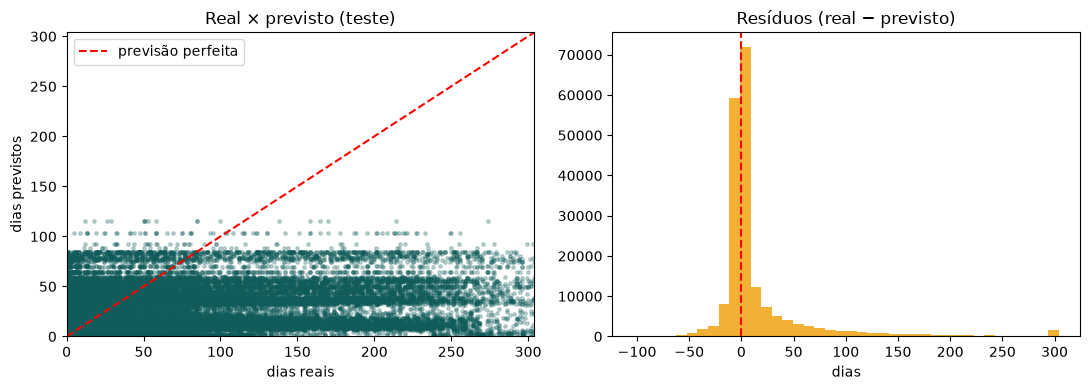

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lim = float(np.quantile(y_teste, .99))
ax[0].scatter(y_teste, previsoes, s=6, alpha=.25, color="#0f5c5a")
ax[0].plot([0, lim], [0, lim], "r--", label="previsão perfeita")
ax[0].set_xlim(0, lim); ax[0].set_ylim(0, lim); ax[0].set_xlabel("dias reais"); ax[0].set_ylabel("dias previstos")
ax[0].set_title("Real × previsto (teste)"); ax[0].legend()
res = (y_teste - previsoes).clip(-lim, lim)
ax[1].hist(res, bins=40, color="#f2b134"); ax[1].axvline(0, color="r", ls="--")
ax[1].set_title("Resíduos (real − previsto)"); ax[1].set_xlabel("dias")
plt.tight_layout(); plt.show()

In [10]:
erro_cat = (pd.DataFrame({"categoria": X_teste["categoria"].values, "erro_abs": np.abs(y_teste.values - previsoes)})
            .groupby("categoria")["erro_abs"].agg(["mean", "count"]).round(2).sort_values("mean"))
erro_cat.columns = ["MAE (dias)", "n no teste"]
erro_cat

,MAE (dias),n no teste
categoria,,
Árvore com risco de queda,2.59,3872
Descarte irregular de lixo,2.80,34173
Buraco na via,20.27,94712
Bueiro entupido,25.58,17393
Calçada danificada,37.58,1907
Poda de árvore,45.80,41237
Sinalização de trânsito danificada,48.63,3201


### O que o modelo aprendeu (importância das variáveis)

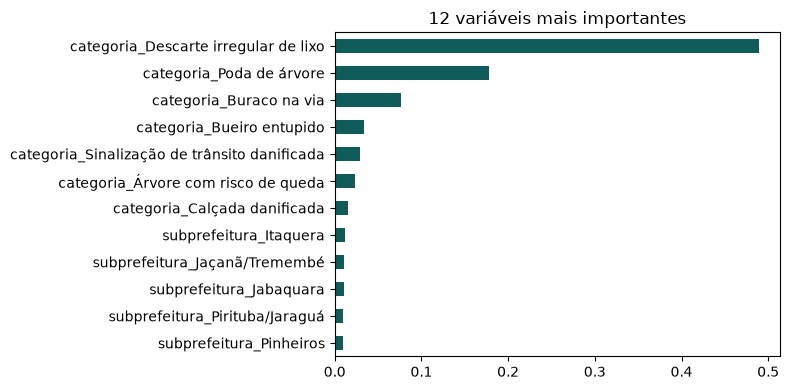

In [11]:
interno = modelo.regressor_   # o pipeline dentro do TransformedTargetRegressor
nomes = interno.named_steps["prep"].get_feature_names_out()
imp = pd.Series(interno.named_steps["modelo"].feature_importances_, index=nomes).sort_values(ascending=False)
imp.index = [i.replace("cat__", "") for i in imp.index]
imp.head(12).sort_values().plot.barh(figsize=(8, 4), color="#0f5c5a")
plt.title("12 variáveis mais importantes"); plt.tight_layout(); plt.show()

## 5. Exportar o modelo (`models/modelo_prazo.joblib`)

In [12]:
import joblib
os.makedirs(os.path.join(RAIZ, "models"), exist_ok=True)
modelo.fit(X, y)   # versão final usa todos os dados; as métricas acima são do treino/teste separado
joblib.dump({"pipeline": modelo, "metricas": metricas, "features": FEATURES, "usa_mes": False, "alvo": "log1p(dias)",
             "categorias_treino": {k: int(v) for k, v in df["categoria"].value_counts().items()}},
            os.path.join(RAIZ, "models", "modelo_prazo.joblib"), compress=3)
print("salvo em models/modelo_prazo.joblib")

salvo em models/modelo_prazo.joblib


In [13]:
# Teste de sanidade: exatamente o corpo que a API recebe (Documento Base 7.3)
exemplo = pd.DataFrame([{"categoria": "Buraco na via", "subprefeitura": df["subprefeitura"].iloc[0], "mes": 11, "dia_semana": 2}])
print("Prazo previsto (dias):", int(round(float(joblib.load(os.path.join(RAIZ, "models", "modelo_prazo.joblib"))["pipeline"].predict(exemplo)[0]))))

Prazo previsto (dias): 10


## 6. Conclusões
* **Comparação dos modelos (na ordem das aulas):** em dias brutos, a Regressão Linear (MAE 30,2) e a Árvore de Decisão (28,4) erraram mais do que uma simples tabela com a mediana de cada categoria (24,5). Quando treinamos em log(1 + dias), a Árvore já passou a tabela (23,9) e o Random Forest foi o melhor (23,3, sem o mês). Escolhemos o Random Forest sabendo que ele é mais difícil de explicar do que a árvore.
* **Ganhou do baseline, mas por pouco:** 23,3 dias de erro médio contra 24,5 da tabela de medianas, uma diferença de 1,1 dia (4,6%). Na validação cruzada com 5 folds deu 23,28 ± 0,35, então o resultado não foi sorte da divisão dos dados.
* **Por que o R² é baixo:** R² de 0,058 e RMSE de 61,0. O modelo explica pouco da variação porque alguns chamados levam centenas de dias e nenhuma das 4 informações da abertura explica o motivo.
* **Onde erra menos e onde erra mais:** Árvore com risco (2,6 dias) e Descarte (2,8) fecham rápido e são fáceis de prever. Buraco erra 20,3 dias; Bueiro, 25,6; Calçada, 37,6; Poda, 45,8; e Sinalização, 48,6.
* **Teste no tempo (treino 2020–2022, teste 2023):** 37,8 dias sem o mês, 38,2 com o mês e 38,7 na tabela de medianas. O mês piora a previsão do futuro, então tiramos o mês do modelo (a API continua aceitando o campo). Também vimos que prever o futuro é mais difícil do que prever chamados sorteados do mesmo período.
* **Limitações:** temos poucas variáveis; o "prazo" do SP156 vai até o órgão fechar o protocolo, não necessariamente até o conserto; os dados incluem a pandemia e não têm fev–mar/2021 nem abr–jun/2023 (o portal hoje já publica o 2º e o 4º trimestres de 2023, que podem entrar num próximo treino); e Iluminação fica sem previsão. Para o cidadão, mostramos a previsão como estimativa, nunca como garantia.